# E2 — Hyperparameter tuning of the main model (M4)

This notebook records how the main model's hyperparameters were chosen, and shows the saved results.
Every number here comes from files in `results/`, so **you do not need to run the training to check the work**.

**How to read it.** Each stage changes one variable, starts from the previous stage's winner, and uses one seed on the
validation set. The test set is never loaded. The final configuration is re-run on three seeds (4012, 4013, 4014).
The decisions and the reasons for them are in *Stage decisions* below; the limitations are listed after them.

## How to use this notebook

- **Default (`RUN_TRAINING = False`)**: reads the saved results in `experiments/E2/results/`, and checks the frozen configuration (written in the configuration cell) against the saved final run. No GPU, no Google Drive and no internet are needed. Run from a downloaded or cloned copy of the repository.
- **Training (`RUN_TRAINING = True`)**: the original Colab procedure on a T4 GPU, with results written to Google Drive. The three final seeds took 32.5 minutes in the saved log. It is not needed for marking.
- **Saved outputs**: the tables are written as CSV, the plot as PNG, and the training logs as text files. The trained model weights are in `experiments/E2/checkpoints/`.

## Configuration

All settings that control this notebook are in the next cell. The main model's values are written out in full
and checked against the saved configuration file in the repository, so the values shown here are the values that were used.

In [1]:
RUN_TRAINING = False          # False (default, for markers): read the saved results. True: retrain on Colab (T4).
STAGE = 'final'               # 1, 2, 3 or 'final'; used only when RUN_TRAINING is True
SMOKE_TEST = False            # True: 3 epochs per run, separate directory (training only)
SEEDS = [4012, 4013, 4014]    # seeds for the final model
MAX_EPOCHS = 300              # budget for every run, no early stopping
EXPECTED_VALID_ROWS = 1606    # size of the validation split; the test split is not used here

# Frozen main model: every setting of the final E2 run (_commit d0268525). Written here, not read from a file.
FROZEN = {
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model', 'models': ['transformer'],
    'learning_rates': [0.0009], 'seeds': [4012, 4013, 4014], 'optimizer': 'adamw',
    'weight_decay': 0.01, 'momentum': 0.9, 'batch_size': 512, 'max_epochs': 300, 'patience': None,
    'grad_clip': None, 'num_workers': 2, 'embedding_dim': 100, 'hidden_size': 100, 'bidirectional': True,
    'enable_attention': True, 'num_heads': 4, 'num_layers': 2, 'dropout_rate': 0.3, 'pooling': 'cls',
    'enable_pos_emb': True, '_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7',
}
# Data split used by these runs (plan section 0): grouped by goal, seed 4012. Record only.
# Train and validation sizes are from the saved log; the test size is from the README and is not used here.
SPLIT = {'method': 'piqa_to_dataframe, grouped by goal, seed 4012', 'train': 14507, 'valid': 1606, 'test': 1838}

In [2]:
if RUN_TRAINING:
    import torch
    if not torch.cuda.is_available():
        raise SystemExit("No GPU. Runtime > Change runtime type > GPU, then rerun.")
    print("GPU:", torch.cuda.get_device_name(0), "|", torch.__version__)

In [3]:
import os, subprocess, sys
from pathlib import Path

if RUN_TRAINING:

    BRANCH = "baselines"
    REPO = Path("/content/repo")

    if not (REPO / '.git').exists():
        subprocess.run(["git", "clone", "-q", "-b", BRANCH,
                        "https://github.com/RayYouDS/cits4012-NLP-project.git",
                        str(REPO)], check=True)
    os.chdir(REPO)

    # A clone left over from an earlier session can sit on a different branch, or on an older commit
    # of the right branch. The branch name alone does not tell you which code is about to run.
    on = subprocess.check_output(['git', 'rev-parse', '--abbrev-ref', 'HEAD'], text=True).strip()
    if on != BRANCH:
        raise SystemExit(f"/content/repo is on {on}, not {BRANCH}. Delete /content/repo and rerun.")

    subprocess.run(['git', 'fetch', '-q', 'origin', BRANCH], check=True)
    local = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    remote = subprocess.check_output(['git', 'rev-parse', 'FETCH_HEAD'], text=True).strip()
    if local != remote:
        behind = subprocess.check_output(
            ['git', 'rev-list', '--count', f'{local}..{remote}'], text=True).strip()
        raise SystemExit(
            f"/content/repo is at {local[:9]} but origin/{BRANCH} is at {remote[:9]} "
            f"({behind} commits ahead). Delete /content/repo and rerun so the run uses current code.")
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)

    for required in ["scripts/training/run_m3.py",
                     "scripts/tokenizer/piqa_bpe_v3.model", "datasets/PIQA/train.jsonl"]:
        if not Path(required).is_file():
            raise SystemExit(f"{required} missing - clone failed or the branch moved.")

    # Stage 2 compares dropout. Without the wiring every run silently uses 0.1 and the stage
    # would compare three identical models.
    src = Path('scripts/training/run_m3.py').read_text(encoding='utf-8')
    builder = src[src.index('def build_model'):src.index('def build_optimizer')]
    missing = [k for k in ('dropout_rate', 'pooling', 'enable_pos_emb') if k not in builder]
    if missing:
        raise SystemExit(f"build_model does not pass {missing} - this branch predates that wiring.")

    # run_m3 seeds a fresh generator per run, so different seeds do get different batch orders.
    # What preloading removes is the per-epoch reshuffle within a run: the bucket sampler runs once
    # and every epoch then repeats the same batches in the same order.
    if 'preload_dataloader_to_gpu(\n                    train_loader' in src:
        print("NOTE: the training loader is preloaded into a fixed list, so within each run every"
              " epoch sees the same batches in the same order. Seeds still differ from each other.")

    # The commit only describes what runs if nobody edited the checkout. -uno looks at tracked
    # files only, so results written elsewhere and __pycache__ cannot raise a false alarm.
    edited = subprocess.check_output(['git', 'status', '--porcelain', '-uno'], text=True).strip()
    if edited:
        raise SystemExit(f"/content/repo has local edits:\n{edited}\nDelete /content/repo and rerun.")

    COMMIT = subprocess.check_output(['git', 'rev-parse', 'HEAD'], text=True).strip()
    print('branch:', BRANCH, ' commit:', COMMIT[:9], ' clean working tree')

else:
    # Read mode: this notebook sits in experiments/E2 of a downloaded or cloned repository.
    REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'experiments').is_dir())
    HAS_GIT = (REPO / '.git').exists()
    COMMIT = (subprocess.check_output(['git', '-C', str(REPO), 'rev-parse', 'HEAD'], text=True).strip()
              if HAS_GIT else 'not recorded (no .git in this copy)')
    print('repository:', REPO, '| commit:', COMMIT[:9] if HAS_GIT else COMMIT)

repository: /home/claude/m4/e2_verify/repo | commit: not recorded (no .git in this copy)


In [4]:
import json
HAS_GIT = (REPO / '.git').exists()
if not RUN_TRAINING:
    # The saved record of the final run must agree with the settings written in the configuration cell.
    saved_main = json.loads((REPO / 'experiments/E2/results/final_3seed/config.json').read_text(encoding='utf-8'))
    for k, v in FROZEN.items():
        if not k.startswith('_') and k != 'output_dir':
            assert saved_main.get(k) == v, f'{k}: saved run has {saved_main.get(k)}, notebook has {v}'
    assert saved_main['_commit'] == FROZEN['_commit'], 'saved run commit differs from the notebook'
    print('frozen configuration matches the saved final run (final_3seed/config.json)')


frozen configuration matches the saved final run (final_3seed/config.json)


## Where results go

A run is saved only once it finishes; a disconnect loses the run in flight and there is no resume.
Later stages read earlier stages' results off disk, so losing them means starting over.

## Configuration

Each run's config is copied next to its results as `config.json`, so a later stage reads the
winning configuration from disk instead of having it typed in again.

The stage winners are chosen by the rules in *Stage decisions*. `PICK` records the one choice that overrides the
highest-validation rule, so the decision stays visible in the notebook.

In [5]:
from pathlib import Path
if RUN_TRAINING:
    from google.colab import drive
    drive.mount('/content/drive')
    RUN_TAG = 'e2_smoke_300' if SMOKE_TEST else 'e2_full_300'
    OUT_ROOT = Path('/content/drive/MyDrive/cits4012') / RUN_TAG
else:
    OUT_ROOT = REPO / 'experiments/E2/results'
OUT_ROOT.mkdir(parents=True, exist_ok=True)
print("results root ->", OUT_ROOT)

results root -> /home/claude/m4/e2_verify/repo/experiments/E2/results


In [6]:
import json, shutil
import pandas as pd

# Embedded so this runs against the shared branch with nothing pushed first.
BASE = {   'output_dir': 'reports/e2_base',
    'tokenizer': 'scripts/tokenizer/piqa_bpe_v3.model',
    'models': ['transformer'],
    'learning_rates': [0.0003],
    'seeds': [4012],
    'optimizer': 'adam',
    'weight_decay': None,
    'momentum': 0.9,
    'batch_size': 512,
    'max_epochs': 300,
    'patience': None,
    'grad_clip': None,
    'num_workers': 2,
    'embedding_dim': 100,
    'hidden_size': 100,
    'bidirectional': True,
    'enable_attention': True,
    'num_heads': 4,
    'num_layers': 3,
    'dropout_rate': 0.1,
    'pooling': 'cls',
    'enable_pos_emb': True}


def finished(prefixes):
    """(config, summary row) for every finished run whose directory starts with any prefix."""
    if isinstance(prefixes, str):
        prefixes = (prefixes,)
    out = []
    seen = set()
    for d in sorted(d for prefix in prefixes for d in OUT_ROOT.glob(prefix + '*')):
        if d.name in seen:
            continue
        seen.add(d.name)
        summary, config = d / 'm3_summary.csv', d / 'config.json'
        if summary.is_file() and config.is_file():
            cfg = json.load(open(config, encoding='utf-8'))
            for _, row in pd.read_csv(summary).iterrows():
                out.append((d.name, cfg, row))
    return out


# best() ranks by validation accuracy. When McNemar says the top two are a tie, the plan's rule
# is to pick by overfitting gap, then time to best, then parameter count - which best() cannot do
# for you. Record that choice here, keyed by the stage it applies to, rather than deleting
# directories to force the outcome. The chosen directory is written into the next stage's config
# as _from, so the decision stays visible afterwards.
PICK = {
    3: 's2_dropout0.3',
    'final': 's3_layers2',

}


def best(prefixes):
    runs = finished(prefixes)
    if not runs:
        raise SystemExit(f"no finished results under {OUT_ROOT}/{prefixes} - run that stage first.")
    ranked = sorted(runs, key=lambda r: r[2].valid_accuracy, reverse=True)
    chosen = PICK.get(STAGE)
    if chosen:
        match = [r for r in ranked if r[0] == chosen]
        if not match:
            raise SystemExit(f"PICK[{STAGE}] = {chosen!r} is not a finished run under {prefixes}. "
                             f"Available: {[r[0] for r in ranked]}")
        if match[0] is not ranked[0]:
            print(f"PICK[{STAGE}]: using {chosen} instead of the highest validation accuracy "
                  f"({ranked[0][0]}, {ranked[0][2].valid_accuracy:.4f}).")
        ranked = match + [r for r in ranked if r[0] != chosen]
    name, cfg, row = ranked[0]
    print(f"best of {prefixes}: {name}  {cfg['optimizer']} lr={row.learning_rate:g} "
          f"dropout={cfg['dropout_rate']} layers={cfg['num_layers']} -> valid {row.valid_accuracy:.4f}")
    # The margin matters here, not three cells later: this winner is what the next stage builds on.
    if len(ranked) > 1:
        margin = row.valid_accuracy - ranked[1][2].valid_accuracy
        runner = ranked[1]
        print(f"  runner-up {runner[0]} at {runner[2].valid_accuracy:.4f}, margin {margin*100:.2f} pp")
        if margin < 0.0125:
            print("  margin is small. The results cell runs McNemar on these two; if that comes out"
                  " non-significant, the plan's E1 rule says to prefer the smaller overfitting gap,"
                  " then the shorter time, then fewer parameters, and to record the choice.")
    # The learning rate comes from the row (a stage sweeps several); everything else from its config.
    keep = {k: cfg[k] for k in ('optimizer', 'weight_decay', 'momentum',
                                'dropout_rate', 'num_layers', 'num_heads')}
    keep['learning_rates'] = [float(row.learning_rate)]
    keep['_from'] = name
    return keep


def job(name, **overrides):
    cfg = dict(BASE)
    cfg['seeds'] = [4012]
    cfg['output_dir'] = str(OUT_ROOT / name)
    cfg.update(overrides)
    if SMOKE_TEST:
        cfg['max_epochs'] = 3
    return name, cfg


if STAGE == 1:
    # The plan's grid: E1's best learning rate divided by 3, itself, and times 3.
    lr = BASE['learning_rates'][0]
    GRID = [float(f'{x:.2g}') for x in (lr / 3, lr, lr * 3)]
    print('learning rates:', GRID)
    # One learning rate per invocation. run_m3 writes m3_summary.csv only after every run in
    # a config finishes, so a disconnect part way through a three-rate config throws away the
    # rates that already finished. One rate per directory costs a little startup and keeps them.
    JOBS = []
    for optimizer, grid, decay in (('adam', GRID, None),
                                   ('adamw', GRID, 0.01),
                                   ('sgd', [0.01, 0.03, 0.1], None)):
        for rate in grid:
            JOBS.append(job(f's1_{optimizer}_lr{rate:g}', optimizer=optimizer,
                            learning_rates=[rate], weight_decay=decay))

elif STAGE == 2:
    keep = best('s1_')
    # 0.1 is already covered by stage 1.
    JOBS = [job(f's2_dropout{d}', **{**keep, 'dropout_rate': d}) for d in (0.0, 0.3)]

elif STAGE == 3:
    # Stage 2 only ran dropout 0.0 and 0.3 because 0.1 is the stage 1 winner. Looking at s2_ alone
    # would throw that candidate away, so stage 3 starts from the best of stage 1 and stage 2.
    keep = best(('s1_', 's2_'))
    # Depth, not head count: head count leaves the parameter total unchanged, so the plan's
    # "fewer parameters" tie-break cannot separate 2 heads from 4.
    JOBS = [job('s3_layers2', **{**keep, 'num_layers': 2})]

elif STAGE == 'final':
    keep = best(('s1_', 's2_', 's3_'))
    name, cfg = job('final_3seed', **keep)
    cfg['seeds'] = [4012, 4013, 4014]
    JOBS = [(name, cfg)]

else:
    raise SystemExit(f"STAGE must be 1, 2, 3 or 'final', got {STAGE!r}")


PLAN = []
UNVERIFIED = []
for name, cfg in JOBS:
    cfg['_commit'] = COMMIT
    out = Path(cfg['output_dir'])
    if (out / 'm3_summary.csv').is_file():
        # Reusing a finished directory is only safe if it was produced by this exact plan.
        old = json.load(open(out / 'config.json', encoding='utf-8'))
        # Underscore keys are metadata. A key absent from one side falls back to the model's
        # default, so writing pooling='cls' explicitly does not invalidate an earlier run that
        # relied on the same default.
        defaults = {'pooling': 'cls', 'enable_pos_emb': True,
                    'include_goal': True, 'dropout_rate': 0.1}
        differs = sorted(k for k in set(old) | set(cfg)
                         if not k.startswith('_') and k != 'output_dir'
                         and old.get(k, defaults.get(k)) != cfg.get(k, defaults.get(k)))
        if differs:
            raise SystemExit(f"{out} is finished but its config differs on {differs}. "
                             f"Move or delete that directory, or revert the change.")
        old_commit = old.get('_commit')
        if old_commit is None:
            UNVERIFIED.append(name)
        elif old_commit != COMMIT and not HAS_GIT:
            print(f"  {name}: produced at {old_commit[:9]}; no .git in this copy, so the code check is skipped")
        elif old_commit != COMMIT:
            # A different commit only matters if it changed code this experiment runs. Baseline
            # scripts and documentation move independently and must not invalidate results.
            touched = subprocess.check_output(
                ['git', 'diff', '--name-only', f'{old_commit}..{COMMIT}', '--',
                 'scripts/training/', 'scripts/models/', 'scripts/data_loader/',
                 'scripts/evaluation/', 'scripts/tokenizer/', 'datasets/'],
                text=True).split()
            if touched:
                raise SystemExit(
                    f"{out} was produced at {old_commit[:9]}, and {COMMIT[:9]} changes code it "
                    f"depends on: {touched}. Move or delete that directory and rerun.")
            print(f"  {name}: produced at {old_commit[:9]}, reused - the difference to "
                  f"{COMMIT[:9]} is outside the code this experiment runs")
        print(f"skip {name} - already finished")
        continue
    # config.json is written here before the run starts, so a directory holding only that has
    # not been used yet and re-running this cell is harmless. Anything else without a summary
    # is a run that died part way: skipping it would hide the gap, reusing the directory would
    # mix two attempts.
    leftovers = sorted(p.name for p in out.glob('*') if p.name != 'config.json') if out.exists() else []
    if leftovers:
        raise SystemExit(f"{out} holds {leftovers[:4]} but no m3_summary.csv - a run died there. "
                         f"Delete that directory, then rerun this cell.")
    out.mkdir(parents=True, exist_ok=True)
    path = f'/content/e2_{name}.json'
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(cfg, f, indent=2)
    shutil.copy(path, out / 'config.json')
    PLAN.append((name, path, cfg))
    print(f"  {name:16s} {cfg['optimizer']:6s} lr={cfg['learning_rates']} "
          f"dropout={cfg['dropout_rate']} layers={cfg['num_layers']} seeds={cfg['seeds']}")

if UNVERIFIED:
    print(f"\nWARNING: {UNVERIFIED} carry no _commit, so the code that produced them cannot be"
          f" checked against {COMMIT[:9]}. They were written before this notebook started"
          f" recording it. Delete and rerun them if you want that guarantee.")

if PLAN and not RUN_TRAINING:
    raise SystemExit(f"{len(PLAN)} run(s) are not in results/ ({[n for n, _, _ in PLAN]}). "
                     "Read mode cannot train them: copy the saved folders, or set RUN_TRAINING = True on Colab.")
if RUN_TRAINING:
    n_runs = sum(len(c['learning_rates']) * len(c['seeds']) for _, _, c in PLAN)
    print(f"\nstage {STAGE}: {n_runs} runs to train, about {n_runs * 10.7:.0f} min on a T4 (3 seeds took 32.5 min in the saved log)")
else:
    print(f"\nstage {STAGE}: all runs are already in results/. Nothing to train.")

PICK[final]: using s3_layers2 instead of the highest validation accuracy (s1_adamw_lr0.0009, 0.6090).
best of ('s1_', 's2_', 's3_'): s3_layers2  adamw lr=0.0009 dropout=0.3 layers=2 -> valid 0.6040
  runner-up s1_adamw_lr0.0009 at 0.6090, margin -0.50 pp
  margin is small. The results cell runs McNemar on these two; if that comes out non-significant, the plan's E1 rule says to prefer the smaller overfitting gap, then the shorter time, then fewer parameters, and to record the choice.
  final_3seed: produced at d0268525b; no .git in this copy, so the code check is skipped
skip final_3seed - already finished

stage final: all runs are already in results/. Nothing to train.


## Stage decisions

| Stage | Variable | Candidates | Winner | Why (validation set) |
|---|---|---|---|---|
| 1 | Optimiser and learning rate | Adam, AdamW, SGD; 9 runs, one seed | AdamW, lr 9e-4 | Highest validation accuracy, 0.6090. Its runner-up Adam 9e-4 (0.6021) is not significantly different (McNemar χ² = 0.297, p = 0.586). The tie rule favours AdamW 9e-4: smaller gap (0.389 vs 0.398), shorter time to best (153 vs 233). |
| 2 | Dropout | 0.0, 0.1 (stage 1), 0.3 | 0.3 | Dropout 0.1 (0.6090) and 0.3 (0.5971) differ by 1.19 pp, not significant (χ² = 0.694, p = 0.405). The tie rule picks 0.3 because its overfitting gap is smaller (0.298 vs 0.389). Recorded as `PICK[3]`. |
| 3 | Depth | 2 and 3 layers | 2 layers | 2 layers: 0.6040, gap 0.295, 933,357 parameters. 3 layers: 0.5971, gap 0.298. The gap difference is 0.003, well below the noise, so this decision is weakly supported. The McNemar test for this pair was not run. |
| Final | Three seeds | 4012, 4013, 4014 | the stage 3 winner | Validation accuracy at the best epoch 0.5940 ± 0.0081 (sample s.d.); plateau mean 0.5797. |

**Override.** Ranking the stage 1–3 runs by validation accuracy alone would choose the stage 1 configuration
(AdamW 9e-4, dropout 0.1, 3 layers, 0.6090). That configuration is not on the staged path, because stage 2 chose dropout 0.3. The override `PICK['final'] = 's3_layers2'` keeps the decisions consistent. The override pair differ by 0.50 pp, McNemar χ² = 0.099, p = 0.753 (not significant), so the choice rests on the tie rule, not on accuracy.

## Run (training only)

Skipped when `RUN_TRAINING = False`. Each run's output is written to `results/<run>/logs/`.

In [7]:
import time
if not RUN_TRAINING:
    print("Training skipped (RUN_TRAINING = False). The saved results are read in the next sections.")
else:
    LOG_DIR = OUT_ROOT / 'logs'
    LOG_DIR.mkdir(exist_ok=True)
    for name, path, cfg in PLAN:
        started = time.time()
        log_path = LOG_DIR / f'{name}.log'
        proc = subprocess.Popen(
            [sys.executable, '-u', '-m', 'scripts.training.run_m3', '--config', path],
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1,
        )
        with open(log_path, 'w', encoding='utf-8') as log:
            for line in proc.stdout:
                log.write(line)
        proc.wait()
        if proc.returncode:
            raise SystemExit(f"{name} exited with code {proc.returncode}; see {log_path}")
        print(f"{name} done in {(time.time() - started) / 60:.1f} min; log: {log_path}")

Training skipped (RUN_TRAINING = False). The saved results are read in the next sections.


## Results (all runs)

One row per run, sorted by validation accuracy at the best epoch. `plateau_mean` is the mean over the second half of training. Saved to `e2_stage_table.csv`.

In [8]:
import math

runs = finished('')
if not runs:
    print("nothing finished yet")
else:
    rows = []
    for name, cfg, row in runs:
        # valid_accuracy is the best validation accuracy over all epochs
        # plateau_mean averages the second half of the same curve as a second opinion.
        run_id = f"m3_{row.model}_lr{row.learning_rate:g}_seed{int(row.seed)}"
        hist = OUT_ROOT / name / f"{run_id}_history.csv"
        if hist.is_file():
            curve = pd.read_csv(hist).valid_accuracy
            plateau = round(float(curve.iloc[len(curve) // 2:].mean()), 4)
        else:
            plateau = None
        rows.append({'_pred': str(OUT_ROOT / name / f"{run_id}_val_predictions.csv"),
                     'stage': name, 'optimizer': cfg['optimizer'],
                     'lr': row.learning_rate, 'weight_decay': cfg['weight_decay'],
                     'dropout': cfg['dropout_rate'], 'layers': cfg['num_layers'],
                     'heads': cfg['num_heads'], 'seed': int(row.seed),
                     'best_epoch': int(row.best_epoch), 'epochs_run': int(row.epochs_run),
                     'valid': round(row.valid_accuracy, 4),
                     'plateau_mean': plateau, 'gap': round(row.gap_at_best, 3),
                     'params': int(row.params)})
    table = pd.DataFrame(rows).sort_values('valid', ascending=False).reset_index(drop=True)
    display(table.drop(columns=['_pred']))
    table.drop(columns=['_pred']).to_csv(OUT_ROOT / 'e2_stage_table.csv', index=False)

    # sqrt(0.25/1606) = 1.25 pp is the standard error of a single accuracy, not of the paired
    # difference between two models scored on the same 1606 questions. It is a rough yardstick
    # only. McNemar on the two prediction files is the test the plan actually specifies.
    print(f"Rough yardstick: 1 s.e. on a single accuracy = {math.sqrt(0.25/1606)*100:.2f} pp "
          f"(n = 1606). Not a paired test.")

    if len(table) > 1:
        top, second = table.iloc[0], table.iloc[1]
        print(f"Top two differ by {(top.valid - second.valid)*100:.2f} pp "
              f"({top.stage} vs {second.stage}).")
        try:
            try:
                from scripts.evaluation.evaluate import mcnemar_test
            except ImportError:   # scripts/ not on the path: same continuity-corrected test, computed here
                import math
                def mcnemar_test(a, b):
                    only_a = int((a & ~b).sum()); only_b = int((~a & b).sum())
                    chi2 = (abs(only_a - only_b) - 1) ** 2 / (only_a + only_b)
                    return {'only_a': only_a, 'only_b': only_b, 'chi2': chi2,
                            'p_value': math.erfc(math.sqrt(chi2 / 2))}
            a = pd.read_csv(top._pred)[['row_id', 'correct']]
            b = pd.read_csv(second._pred)[['row_id', 'correct']]
            merged = a.merge(b, on='row_id', suffixes=('_a', '_b'))
            result = mcnemar_test(merged.correct_a.to_numpy().astype(bool),
                                  merged.correct_b.to_numpy().astype(bool))
            verdict = 'significant' if result['p_value'] < 0.05 else 'NOT significant'
            print(f"McNemar on the same {len(merged)} questions: only_a={result['only_a']} "
                  f"only_b={result['only_b']} chi2={result['chi2']:.3f} p={result['p_value']:.4f}"
                  f"  -> {verdict} at alpha 0.05")
            if result['p_value'] >= 0.05:
                print("The plan's E1 rule for a tie: prefer the smaller overfitting gap, then the"
                      " shorter time to best, then fewer parameters. Record which one you applied.")
        except Exception as exc:
            print(f"McNemar skipped: {exc}")
    if table.plateau_mean.notna().any() and table.sort_values(
            'plateau_mean', ascending=False).index[0] != 0:
        print("best_epoch and plateau_mean disagree about the winner - this stage separated nothing.")

,stage,optimizer,lr,weight_decay,dropout,layers,heads,seed,best_epoch,epochs_run,valid,plateau_mean,gap,params
0,s1_adamw_lr0.0009,adamw,0.0009,0.01,0.1,3,4,4012,153,300,0.6090,0.5862,0.389,999985
1,s3_layers2,adamw,0.0009,0.01,0.3,2,4,4012,203,300,0.6040,0.5877,0.295,933357
2,s1_adam_lr0.0009,adam,0.0009,NaN,0.1,3,4,4012,233,300,0.6021,0.5876,0.398,999985
3,final_3seed,adamw,0.0009,0.01,0.3,2,4,4012,213,300,0.5996,0.5874,0.290,933357
4,s1_adamw_lr0.0003,adamw,0.0003,0.01,0.1,3,4,4012,296,300,0.5996,0.5875,0.394,999985
5,final_3seed,adamw,0.0009,0.01,0.3,2,4,4013,179,300,0.5978,0.5805,0.268,933357
6,s1_sgd_lr0.1,sgd,0.1000,NaN,0.1,3,4,4012,191,300,0.5971,0.5718,0.359,999985
7,s2_dropout0.3,adamw,0.0009,0.01,0.3,3,4,4012,204,300,0.5971,0.5793,0.298,999985
8,s1_adam_lr0.0003,adam,0.0003,NaN,0.1,3,4,4012,295,300,0.5922,0.5773,0.400,999985
9,s1_adam_lr0.0001,adam,0.0001,NaN,0.1,3,4,4012,116,300,0.5897,0.5741,0.195,999985


Rough yardstick: 1 s.e. on a single accuracy = 1.25 pp (n = 1606). Not a paired test.
Top two differ by 0.50 pp (s1_adamw_lr0.0009 vs s3_layers2).


McNemar on the same 1606 questions: only_a=251 only_b=243 chi2=0.099 p=0.7528  -> NOT significant at alpha 0.05
The plan's E1 rule for a tie: prefer the smaller overfitting gap, then the shorter time to best, then fewer parameters. Record which one you applied.
best_epoch and plateau_mean disagree about the winner - this stage separated nothing.


## Training curves (from the saved logs)

Plotted from the per-epoch history files in `results/final_3seed/`, not from a DataFrame held in memory, so the figure can be redrawn from the repository alone.

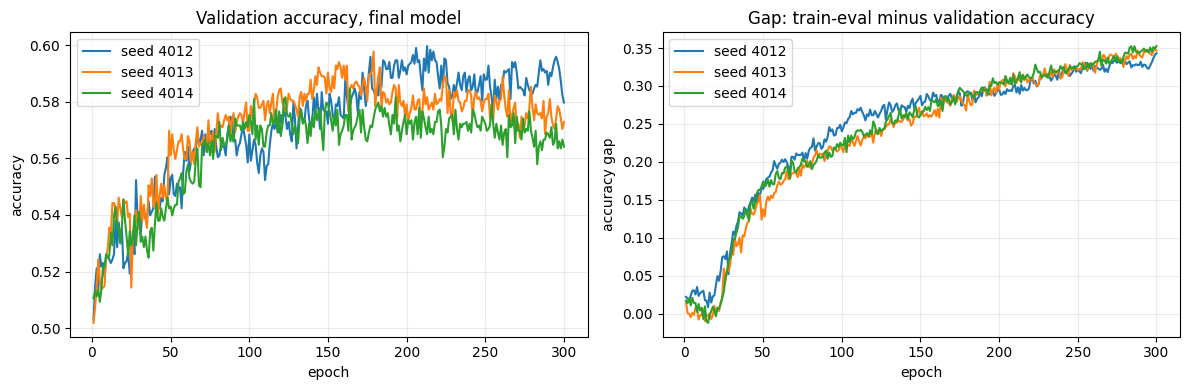

In [9]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for seed in SEEDS:
    h = pd.read_csv(OUT_ROOT / 'final_3seed' / f'm3_transformer_lr0.0009_seed{seed}_history.csv')
    axes[0].plot(h['epoch'], h['valid_accuracy'], label=f'seed {seed}')
    axes[1].plot(h['epoch'], h['train_eval_accuracy'] - h['valid_accuracy'], label=f'seed {seed}')
axes[0].set(title='Validation accuracy, final model', xlabel='epoch', ylabel='accuracy')
axes[1].set(title='Gap: train-eval minus validation accuracy', xlabel='epoch', ylabel='accuracy gap')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
fig.savefig(OUT_ROOT / 'e2_final_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Trained model (state_dict)

The three final checkpoints are in `experiments/E2/checkpoints/`. Each file is a PyTorch `state_dict` (saved by `run_m3.py` with `torch.save(model.state_dict(), ...)`), so it loads into a model built with the same settings, without retraining.

The next cell rebuilds the model from the frozen configuration, loads seed 4012, and recomputes its validation accuracy. The result should match `m3_summary.csv` (0.599626 for seed 4012). **This cell needs the repository code (`scripts/`) and the PIQA data (`datasets/PIQA/`), so it runs in a full copy of the repository. It was not run in the environment that prepared this notebook.**

In [10]:
import warnings
warnings.filterwarnings('ignore')   # library warnings (nested tensors, shuffle) are not results
import sys, torch, sentencepiece as spm
sys.path.insert(0, str(REPO))                       # relative imports from the repository root
from scripts.models.transformer_bi_classifier import TransformerClassifier
from scripts.data_loader.piqa_dataloader import PIQACollator, tokenize_piqa_dataframe, preload_dataloader_to_gpu
from scripts.training.run_m3 import make_loader
from scripts.evaluation.evaluate import evaluate

tokenizer = spm.SentencePieceProcessor(model_file=str(REPO / 'scripts/tokenizer/piqa_bpe_v3.model'))
model = TransformerClassifier(                      # the frozen settings from the configuration cell
    vocab_size=tokenizer.get_piece_size(), embedding_dim=FROZEN['embedding_dim'], padding_idx=tokenizer.pad_id(),
    max_seq_length=2048, num_heads=FROZEN['num_heads'], num_layers=FROZEN['num_layers'],
    dropout_rate=FROZEN['dropout_rate'], enable_pos_emb=FROZEN['enable_pos_emb'], pooling=FROZEN['pooling'])
ckpt = REPO / 'experiments/E2/checkpoints/m3_transformer_lr0.0009_seed4012_best.pt'
model.load_state_dict(torch.load(ckpt, map_location='cpu'))   # strict: fails if the architecture differs
model.eval()

_, valid_df, _ = tokenize_piqa_dataframe(REPO / 'datasets/PIQA', tokenizer)
valid_df = valid_df.reset_index(drop=True)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
batches = preload_dataloader_to_gpu(make_loader(valid_df, PIQACollator(tokenizer), 512, 0, False, shuffle=False), device)
metrics, _ = evaluate(model, batches, device)
saved = pd.read_csv(OUT_ROOT / 'final_3seed' / 'm3_summary.csv').set_index('seed')['valid_accuracy'][4012]
print(f"loaded accuracy {metrics['accuracy']:.6f} | saved {saved:.6f} | difference {abs(metrics['accuracy'] - saved):.6f}")

loaded accuracy 0.599626 | saved 0.599626 | difference 0.000000


## Environment and data

- **Data**: goal-grouped split, seed 4012, tokenizer `piqa_bpe_v3.model` (vocabulary 8,000). Training 14,507 questions and validation 1,606 (from the saved log). The test split is 1,838 questions by the README; it was not loaded here.
- **Training environment** (Colab, the runs in `results/`): Tesla T4, PyTorch 2.11.0+cu130, Python 3.13, code commit `d0268525` on `baselines`.
- **Randomness**: seeds are fixed (4012, 4013, 4014). GPU kernels are not fully deterministic, so a rerun can differ slightly. The same configuration and seed gave 0.6040 in stage 3 and 0.5996 in the final run (0.44 pp); the cause is likely GPU nondeterminism, not confirmed.

## Limitations

1. **One seed per stage.** Differences below about 1.25 pp are within noise (one standard error on 1,606 questions). Stage choices rest on the tie rules, not on accuracy.
2. **Training loader is preloaded.** The training batches are fixed in one list before training, so every epoch of a run sees the same batches in the same order. Different seeds still change the order between runs. This is a known limitation of the run; it was not changed here.
3. **Budget.** Every run uses 300 epochs with no early stopping, the budget of the E1 run. The plan's 1000-epoch stress test was not run. Three stage 1 runs peaked at epochs 293–296, so they may be budget-limited.
4. **Learning-rate grid edge.** The chosen rate (9e-4) is the top of the grid.
5. **Best epoch and plateau disagree.** The plateau mean puts stage 3's winner (0.5877) just above stage 1's (0.5862), while the best-epoch rule puts them the other way. The two differ by 0.15 pp, so this stage does not separate them clearly.
6. **Overfitting is large in every run.** Final-model training accuracy in evaluation mode is about 0.85–0.89, against about 0.59 on validation.